<a href="https://colab.research.google.com/github/marianafernandes427/Git101/blob/main/SCAA_final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Drive

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## Aceder ficheiro

In [2]:
import os
import pandas as pd

pasta_caminho = '/content/drive/MyDrive/SCAA/data_proj'

try:
    arquivos = os.listdir(pasta_caminho)
    print("Arquivos encontrados em SCAA/data_proj:")
    for arquivo in arquivos:
        print(f"- {arquivo}")

    print("\n--- Exibindo o cabeçalho de cada arquivo ---\n")
    for arquivo in arquivos:
        caminho_completo = os.path.join(pasta_caminho, arquivo)

        # Processa apenas se for um arquivo de dados (CSV)
        if arquivo.endswith('.csv'):
            print(f"\nCabeçalho do arquivo: {arquivo}")
            df = pd.read_csv(caminho_completo)
            display(df.head(2))
            print("-" * 50)
except Exception as e:
    print("Erro ao aceder SCAA/data_proj ou ler os arquivos.")
    print("Detalhes do erro:", e)

Arquivos encontrados em SCAA/data_proj:
- sample_submission.csv
- test.csv
- train.csv

--- Exibindo o cabeçalho de cada arquivo ---


Cabeçalho do arquivo: sample_submission.csv


,row_id,unplanned_outage_next_30d
0,0,0
1,1,0


--------------------------------------------------

Cabeçalho do arquivo: test.csv


,rf_spectrum_telemetry_bin_43,oil_particle_count_log,rf_spectrum_telemetry_bin_27,cycle_index,rf_spectrum_telemetry_bin_58,rf_spectrum_telemetry_bin_51,post_shutdown_log_delta,rf_spectrum_telemetry_bin_11,rf_spectrum_telemetry_bin_25,rf_spectrum_telemetry_bin_17,...,rf_spectrum_telemetry_bin_54,sensor_channel_dead_99,rf_spectrum_telemetry_bin_02,rf_spectrum_telemetry_bin_13,rf_spectrum_telemetry_bin_16,rf_spectrum_telemetry_bin_20,vibration_axial_rms_mm_s,post_incident_triage_metric,rf_spectrum_telemetry_bin_66,row_id
0,0.170339,4.425919,-2673.979635,0,0.930110,-13841.679993,6.566499,20.648066,0.662997,-200.367407,...,1620.794788,NaN,82.409150,-1.259711,-2.081819,82.257664,5.688586,83.856944,-12070.461031,1
1,-0.005460,3.880465,1507.947020,1,-0.488913,20685.061392,1.504431,-78.207132,0.718841,-96.245574,...,7667.229779,NaN,-135.405387,-1.368301,0.628116,13.417814,3.792747,84.747392,-14479.126870,2


--------------------------------------------------

Cabeçalho do arquivo: train.csv


,rf_spectrum_telemetry_bin_43,oil_particle_count_log,rf_spectrum_telemetry_bin_27,cycle_index,rf_spectrum_telemetry_bin_58,rf_spectrum_telemetry_bin_51,post_shutdown_log_delta,rf_spectrum_telemetry_bin_11,rf_spectrum_telemetry_bin_25,rf_spectrum_telemetry_bin_17,...,rf_spectrum_telemetry_bin_54,sensor_channel_dead_99,rf_spectrum_telemetry_bin_02,rf_spectrum_telemetry_bin_13,rf_spectrum_telemetry_bin_16,rf_spectrum_telemetry_bin_20,vibration_axial_rms_mm_s,post_incident_triage_metric,rf_spectrum_telemetry_bin_66,unplanned_outage_next_30d
0,0.608062,4.252230,8556.268676,0,-0.306836,-6697.004621,0.000000,45.205328,-0.767761,25.07804,...,-13641.486111,NaN,-83.491451,-0.434892,-0.817820,136.123914,5.346971,12.147916,-10534.348292,0
1,-1.146608,4.034391,5649.470928,1,-0.000159,-3382.474863,5.707891,42.888103,0.353533,-18.70261,...,-7994.677289,NaN,-69.829082,-0.626385,-0.269559,-55.077479,7.964533,84.166153,515.627812,1


--------------------------------------------------


In [3]:
import os
import pandas as pd
import re

caminho_train = os.path.join('/content/drive/MyDrive/SCAA/data_proj', 'train.csv')
caminho_test = os.path.join('/content/drive/MyDrive/SCAA/data_proj', 'test.csv')

# Carrega o arquivo train.csv
df_train = pd.read_csv(caminho_train)

# Carrega o arquivo test.csv
df_test = pd.read_csv(caminho_test)

# Exibe as primeiras linhas e o tamanho do DataFrame
print(f"Tamanho do dataset de treino: {df_train.shape[0]} linhas e {df_train.shape[1]} colunas.\n")
display(df_train.head())
display(df_test.head())

Tamanho do dataset de treino: 8029 linhas e 92 colunas.



,rf_spectrum_telemetry_bin_43,oil_particle_count_log,rf_spectrum_telemetry_bin_27,cycle_index,rf_spectrum_telemetry_bin_58,rf_spectrum_telemetry_bin_51,post_shutdown_log_delta,rf_spectrum_telemetry_bin_11,rf_spectrum_telemetry_bin_25,rf_spectrum_telemetry_bin_17,...,rf_spectrum_telemetry_bin_54,sensor_channel_dead_99,rf_spectrum_telemetry_bin_02,rf_spectrum_telemetry_bin_13,rf_spectrum_telemetry_bin_16,rf_spectrum_telemetry_bin_20,vibration_axial_rms_mm_s,post_incident_triage_metric,rf_spectrum_telemetry_bin_66,unplanned_outage_next_30d
0,0.608062,4.252230,8556.268676,0,-0.306836,-6697.004621,0.000000,45.205328,-0.767761,25.078040,...,-13641.486111,NaN,-83.491451,-0.434892,-0.817820,136.123914,5.346971,12.147916,-10534.348292,0
1,-1.146608,4.034391,5649.470928,1,-0.000159,-3382.474863,5.707891,42.888103,0.353533,-18.702610,...,-7994.677289,NaN,-69.829082,-0.626385,-0.269559,-55.077479,7.964533,84.166153,515.627812,1
2,0.958301,4.440323,-4859.907773,2,1.530001,3742.752264,5.035072,30.435138,0.667571,-122.551251,...,3608.922084,NaN,-187.477031,-0.367608,0.971477,-33.418832,7.761246,86.966643,-7869.174330,1
3,-0.287148,4.135007,-1401.343253,3,-0.115152,-9789.763020,1.670989,-90.024720,-0.345246,-61.332649,...,-1296.284355,NaN,75.761246,-0.304261,-1.185815,-199.465582,6.539467,81.366577,18927.452799,1
4,-1.925066,3.883130,-4700.530519,4,-0.469639,-2506.770613,0.000000,32.810263,0.247279,-73.876420,...,-23205.012738,NaN,204.881844,-0.374326,-0.580881,66.830051,6.967322,13.295296,2958.937728,0


,rf_spectrum_telemetry_bin_43,oil_particle_count_log,rf_spectrum_telemetry_bin_27,cycle_index,rf_spectrum_telemetry_bin_58,rf_spectrum_telemetry_bin_51,post_shutdown_log_delta,rf_spectrum_telemetry_bin_11,rf_spectrum_telemetry_bin_25,rf_spectrum_telemetry_bin_17,...,rf_spectrum_telemetry_bin_54,sensor_channel_dead_99,rf_spectrum_telemetry_bin_02,rf_spectrum_telemetry_bin_13,rf_spectrum_telemetry_bin_16,rf_spectrum_telemetry_bin_20,vibration_axial_rms_mm_s,post_incident_triage_metric,rf_spectrum_telemetry_bin_66,row_id
0,0.170339,4.425919,-2673.979635,0,0.930110,-13841.679993,6.566499,20.648066,0.662997,-200.367407,...,1620.794788,NaN,82.409150,-1.259711,-2.081819,82.257664,5.688586,83.856944,-12070.461031,1
1,-0.005460,3.880465,1507.947020,1,-0.488913,20685.061392,1.504431,-78.207132,0.718841,-96.245574,...,7667.229779,NaN,-135.405387,-1.368301,0.628116,13.417814,3.792747,84.747392,-14479.126870,2
2,1.322392,3.684630,1173.592471,2,-0.763721,-7011.760673,0.000000,-77.335201,0.610115,12.143288,...,4942.507096,NaN,8.759286,0.701421,0.829578,70.059366,5.932534,9.517445,-11705.034636,3
3,-0.700405,4.177588,-9185.753429,3,0.173030,-8886.302125,0.000000,24.269860,1.112293,-68.164980,...,-2100.350698,NaN,-62.375588,1.002153,-0.003420,-133.318416,NaN,23.991834,-6324.635248,4
4,1.376062,4.937959,12753.032884,4,-0.972305,-431.389566,0.000000,-129.024304,0.630835,-29.282390,...,22933.016273,NaN,-68.095240,1.015051,-1.913660,-66.761264,3.353938,13.856466,-9465.424076,5


### Análise Estrutural e Qualidade dos dados

In [4]:
# Dimensões, nomes e tipo de dados
print(f"Treino: {df_train.shape[0]} linhas × {df_train.shape[1]} colunas")
print(f"Teste: {df_test.shape[0]} linhas × {df_test.shape[1]} colunas")

print("Nomes duplicados no treino:", df_train.columns[df_train.columns.duplicated()].tolist())
print("Nomes duplicados no teste:", df_test.columns[df_test.columns.duplicated()].tolist())

print("\nTipos de dados no treino")
display(df_train.dtypes.astype(str).value_counts().rename_axis("tipo").reset_index(name="numero_colunas"))

print("\nTipos de dados no teste")
display(df_test.dtypes.astype(str).value_counts().rename_axis("tipo").reset_index(name="numero_colunas"))

# Nome da variável alvo (como string)
nome_target = "unplanned_outage_next_30d"

# Comparação dos nomes das colunas, excluindo o nome do target do treino
colunas_features_treino = set(df_train.columns) - {nome_target}
colunas_features_teste = set(df_test.columns)

print("\nConsistência do esquema")
print("Features apenas no treino:", sorted(colunas_features_treino - colunas_features_teste))
print("Features apenas no teste:", sorted(colunas_features_teste - colunas_features_treino))

Treino: 8029 linhas × 92 colunas
Teste: 2006 linhas × 92 colunas
Nomes duplicados no treino: []
Nomes duplicados no teste: []

Tipos de dados no treino


,tipo,numero_colunas
0,float64,88
1,int64,2
2,object,2



Tipos de dados no teste


,tipo,numero_colunas
0,float64,88
1,int64,2
2,object,2



Consistência do esquema
Features apenas no treino: []
Features apenas no teste: ['row_id']


Valores em Falta

In [5]:
# Valores em falta
def auditar_missing(df, nome_conjunto):
    resumo = pd.DataFrame({"valores_em_falta": df.isna().sum(),
        "percentagem_em_falta": df.isna().mean() * 100,
        "valores_preenchidos": df.notna().sum(),
        "valores_distintos": df.nunique(dropna=True)})

    resumo["percentagem_em_falta"] = resumo["percentagem_em_falta"].round(2)
    resumo = resumo.sort_values(["percentagem_em_falta", "valores_em_falta"],ascending=False)
    print(f"\nValores em falta : {nome_conjunto}")
    display(resumo[resumo["valores_em_falta"] > 0])
    print("Colunas sem valores em falta:", int((resumo["valores_em_falta"] == 0).sum()))
    print("Total de células em falta:", int(df.isna().sum().sum()))

    return resumo

resumo_missing_train = auditar_missing(df_train, "treino")
resumo_missing_test = auditar_missing(df_test, "teste")


Valores em falta : treino


,valores_em_falta,percentagem_em_falta,valores_preenchidos,valores_distintos
sensor_channel_dead_99,7878,98.12,151,151
vibration_axial_rms_mm_s,393,4.89,7636,6880
lubricant_dielectric_constant,248,3.09,7781,7754


Colunas sem valores em falta: 89
Total de células em falta: 8519

Valores em falta : teste


,valores_em_falta,percentagem_em_falta,valores_preenchidos,valores_distintos
sensor_channel_dead_99,1968,98.11,38,37
vibration_axial_rms_mm_s,109,5.43,1897,1697
lubricant_dielectric_constant,68,3.39,1938,1933


Colunas sem valores em falta: 89
Total de células em falta: 2145


Duplicados

In [7]:
# Linhas duplicadas e possíveis duplicações de registos
n_duplicados_train = int(df_train.duplicated().sum())
n_duplicados_test = int(df_test.duplicated().sum())

print("Linhas duplicadas exatas no treino:", n_duplicados_train)
print("Linhas duplicadas exatas no teste:", n_duplicados_test)
print("Percentagem de linhas duplicadas no treino:", round(100 * n_duplicados_train / len(df_train), 3), "%")
print("Percentagem de linhas duplicadas no teste:", round(100 * n_duplicados_test / len(df_test), 3), "%")

# Eliminar duplicados
df_train.drop_duplicates(inplace=True)

Linhas duplicadas exatas no treino: 29
Linhas duplicadas exatas no teste: 0
Percentagem de linhas duplicadas no treino: 0.361 %
Percentagem de linhas duplicadas no teste: 0.0 %


Como sensor channel_dead tem muitos valores em falta, remover o modelo

In [8]:
df_train = df_train.drop(columns=['sensor_channel_dead_99'])

In [9]:
df_train.describe()

,rf_spectrum_telemetry_bin_43,oil_particle_count_log,rf_spectrum_telemetry_bin_27,cycle_index,rf_spectrum_telemetry_bin_58,rf_spectrum_telemetry_bin_51,post_shutdown_log_delta,rf_spectrum_telemetry_bin_11,rf_spectrum_telemetry_bin_25,rf_spectrum_telemetry_bin_17,...,temperature_sensor_2_c,rf_spectrum_telemetry_bin_54,rf_spectrum_telemetry_bin_02,rf_spectrum_telemetry_bin_13,rf_spectrum_telemetry_bin_16,rf_spectrum_telemetry_bin_20,vibration_axial_rms_mm_s,post_incident_triage_metric,rf_spectrum_telemetry_bin_66,unplanned_outage_next_30d
count,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,...,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,7607.000000,8000.000000,8000.000000,8000.000000
mean,0.003858,4.136234,-41.401235,2.000000,-0.008270,178.116200,0.635730,-0.590250,-0.002890,-0.365819,...,720.705957,90.439233,-0.618822,-0.008262,0.021101,-0.074503,5.283934,38.145653,-86.401335,0.315000
std,0.994446,0.550087,9964.917477,1.414302,0.996114,9742.660383,1.417479,99.805731,1.002979,99.816015,...,22.995040,9941.465491,100.058958,1.002674,1.001988,98.331955,3.667895,30.101129,9977.353381,0.464545
min,-3.976719,1.794077,-33614.478103,0.000000,-3.827165,-37870.476536,0.000000,-367.960393,-4.164295,-379.363842,...,641.138207,-36860.070636,-437.404280,-3.589355,-3.711059,-347.136739,0.000000,0.814899,-38915.819973,0.000000
25%,-0.673984,3.762326,-6707.552916,1.000000,-0.663957,-6392.851467,0.000000,-67.605071,-0.681273,-67.415224,...,704.994544,-6520.658726,-67.931002,-0.678965,-0.659913,-65.557849,2.392053,16.248033,-6940.228558,0.000000
50%,0.003250,4.128159,-142.525019,2.000000,-0.002983,338.719088,0.000000,-1.288719,0.002284,0.717431,...,720.670669,171.268744,-0.316060,-0.016991,0.012201,1.251807,5.037447,20.953273,-216.123159,0.000000
75%,0.668662,4.512518,6760.370469,3.000000,0.643398,6853.676073,0.542220,66.854655,0.681249,66.632931,...,736.230921,6767.502371,66.731581,0.669856,0.714701,64.978545,7.779918,78.579230,6685.767476,1.000000
max,4.611257,6.194179,34154.181019,4.000000,3.400757,38162.966975,14.902651,359.799690,4.301848,391.818502,...,798.904904,42898.927821,346.431882,3.784136,3.501517,376.732784,20.454417,95.163174,35435.066022,1.000000


In [12]:
print(df_train.dtypes)

rf_spectrum_telemetry_bin_43    float64
oil_particle_count_log          float64
rf_spectrum_telemetry_bin_27    float64
cycle_index                       int64
rf_spectrum_telemetry_bin_58    float64
                                 ...   
rf_spectrum_telemetry_bin_20    float64
vibration_axial_rms_mm_s        float64
post_incident_triage_metric     float64
rf_spectrum_telemetry_bin_66    float64
unplanned_outage_next_30d         int64
Length: 91, dtype: object


## Descrição das Variáveis

* **oil_particle_log_count:** Quantidade de partículas de desgaste presentes no lubrificante, numa escala logarítmica.
* **oil_particle_log_iso:** Nível de contaminação do óleo por partículas, ** descobrir a escala**
* **cycle_index:** Número de 0 a 4 do ciclo de funcionamento da máquina
* **post_shutdown_log_delta:** Variação em escala logarítmica após a paragem da máquina, descobrir qual a medida
* **recent_alarm_event_codes:** Históricos de códigos de alarme recentes
* **sensor_channel_constant:** Valor constante de configuração associado a um canal de aquisição de um sensor
* **rpm:** rotações por minuto
* **lubricant_dieletric_constant:** Constante dielética do lubrificante que representa uma propriedade elétrica do óleo que pode ajudar a identificar alterações na composição, contaminação e degradação
* **bearing_clearance_effieciency:** Indicador de eficiência da folga do rolamento, descobri a métrica
* **vibration_radial_rms_mm_s:** Vibração radial RMS em mm/s
* **vibration_axial_rms_mm_s:** Vibração axial RMS em mm/s
* **exhaust_temp_deviation_c:** Desvio da temperatura dos gases do escape
* **temperature_sensor_2_c:** Temperatura do sensor 2
* **machine_serial_id:** Idenficador da série da máquina
* **sensor_channel_dead_99:** Métrica de triagem após um incidente
* **unplanned_outage_next_30d:** Paragem não planeada nos próximos 30 dias
* **75 colunas acerca da telemetria:** 75 bandas ou intervalos de um espectro de sinal de radiofrequência (RF) recolhido pela telemetria da máquina.

## Target

In [14]:
print(df_train['unplanned_outage_next_30d'].value_counts())

unplanned_outage_next_30d
0    5480
1    2520
Name: count, dtype: int64


## Análise Univariada

## Análise Multivariada

### Correlações

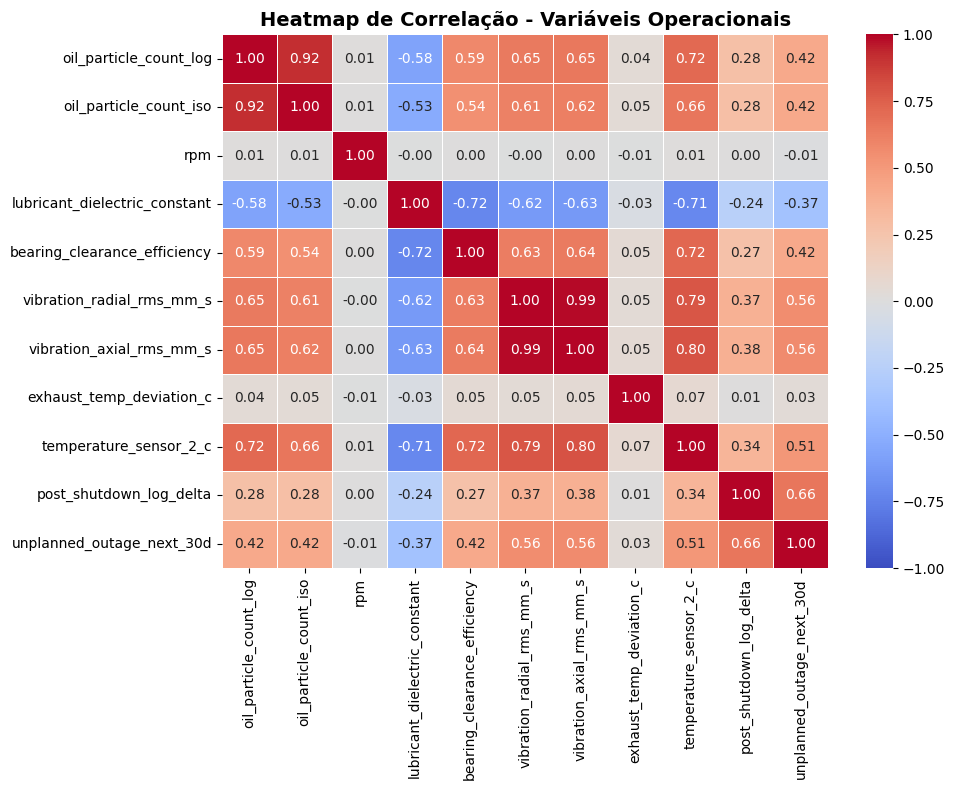

In [20]:
import seaborn as sns
import matplotlib.pyplot as plt

# Selecionar apenas as colunas numéricas que não sejam de telemetria para o heatmap não ficar sobrecarregado
# ou se preferir, todas as variáveis operacionais principais.
cols_operacionais = [
    'oil_particle_count_log',
    'oil_particle_count_iso',
    'rpm',
    'lubricant_dielectric_constant',
    'bearing_clearance_efficiency',
    'vibration_radial_rms_mm_s',
    'vibration_axial_rms_mm_s',
    'exhaust_temp_deviation_c',
    'temperature_sensor_2_c',
    'post_shutdown_log_delta',
    'unplanned_outage_next_30d'
]

# Filtrar colunas existentes no treino
cols_para_corr = [col for col in cols_operacionais if col in df_train.columns]

# Calcular a matriz de correlação
corr_matrix = df_train[cols_para_corr].corr()

# Gerar o Heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    linewidths=0.5
)

plt.title('Heatmap de Correlação - Variáveis Operacionais', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

### VIF

In [17]:
import pandas as pd
import numpy as np
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

# 1. Selecionar as principais variáveis operacionais numéricas
vars_operacionais = [
    'oil_particle_count_log',
    'oil_particle_count_iso',
    'rpm',
    'lubricant_dielectric_constant',
    'bearing_clearance_efficiency',
    'vibration_radial_rms_mm_s',
    'vibration_axial_rms_mm_s',
    'exhaust_temp_deviation_c',
    'temperature_sensor_2_c',
    'post_shutdown_log_delta'
]

# 2. Criar uma cópia dos dados removendo linhas com nulos apenas nestas colunas
df_vif = df_train[vars_operacionais].dropna().copy()

# 3. Adicionar uma constante para o cálculo correto do VIF
X_vif = add_constant(df_vif)

# 4. Calcular o VIF para cada variável
vif_data = pd.DataFrame()
vif_data["Variável"] = X_vif.columns
vif_data["VIF"] = [variance_inflation_factor(X_vif.values, i) for i in range(X_vif.shape[1])]

# Excluir a constante do resultado final para melhor leitura
vif_data = vif_data[vif_data["Variável"] != "const"].sort_values(by="VIF", ascending=False)

print("=== VARIANCE INFLATION FACTOR (VIF) ===")
display(vif_data)

=== VARIANCE INFLATION FACTOR (VIF) ===


,Variável,VIF
7,vibration_axial_rms_mm_s,47.811006
6,vibration_radial_rms_mm_s,45.824213
1,oil_particle_count_log,7.865612
2,oil_particle_count_iso,6.779557
9,temperature_sensor_2_c,4.129373
4,lubricant_dielectric_constant,2.560267
5,bearing_clearance_efficiency,2.553465
10,post_shutdown_log_delta,1.189637
8,exhaust_temp_deviation_c,1.005565
3,rpm,1.000601


### Variáveis Telemétricas

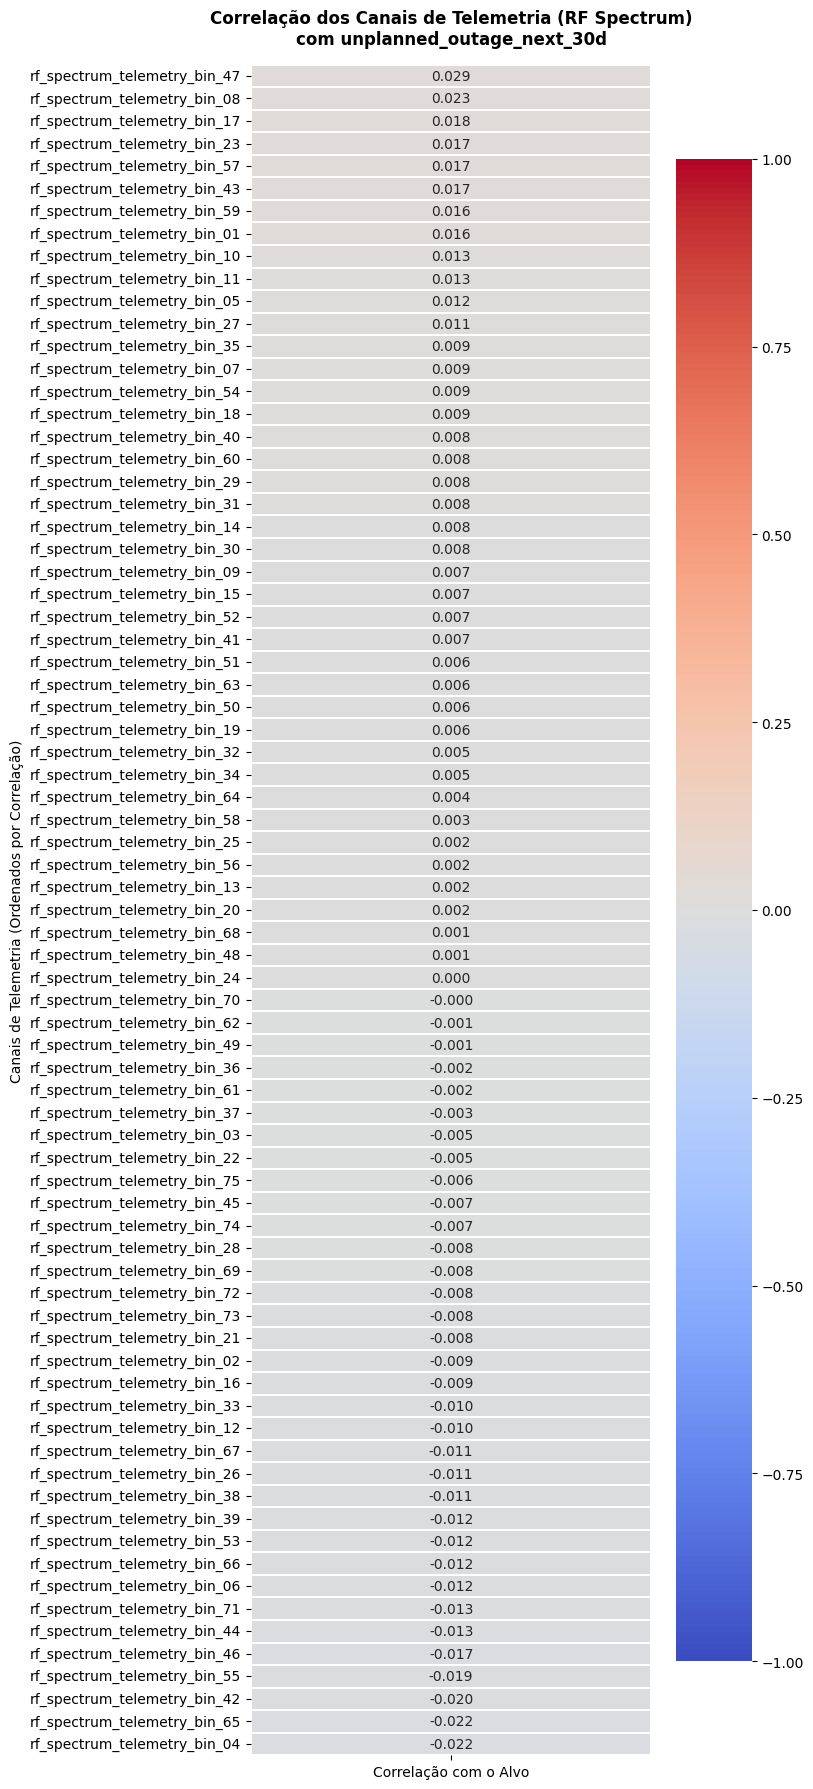

In [18]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Filtrar as 75 colunas de telemetria e a variável alvo
cols_rf = [col for col in df_train.columns if 'rf_spectrum_telemetry' in col]
df_analise = df_train[cols_rf + ['unplanned_outage_next_30d']]

# 2. Calcular a correlação de todas as variáveis com a variável alvo
correlacoes_alvo = df_analise.corr()['unplanned_outage_next_30d'].drop('unplanned_outage_next_30d')

# Converter para DataFrame para facilitar a ordenação e plotagem
df_corr_alvo = correlacoes_alvo.to_frame(name='Correlação com o Alvo').sort_values(by='Correlação com o Alvo', ascending=False)

# 3. Plotar o Heatmap Vertical
plt.figure(figsize=(8, 18))
sns.heatmap(
    df_corr_alvo,
    annot=True,
    fmt=".3f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    cbar=True,
    linewidths=0.3
)

plt.title('Correlação dos Canais de Telemetria (RF Spectrum)\ncom unplanned_outage_next_30d', fontsize=12, fontweight='bold', pad=15)
plt.ylabel('Canais de Telemetria (Ordenados por Correlação)')
plt.tight_layout()
plt.show()

A calcular a Informação Mútua para as 75 colunas de telemetria (isso pode levar alguns segundos)... 

=== TOP 15 CANAIS DE TELEMETRIA COM MAIOR INFORMAÇÃO MÚTUA COM O ALVO ===


,Canal Telemetria,Mutual Information
27,rf_spectrum_telemetry_bin_26,0.012477
57,rf_spectrum_telemetry_bin_38,0.010462
64,rf_spectrum_telemetry_bin_12,0.009385
29,rf_spectrum_telemetry_bin_74,0.008913
36,rf_spectrum_telemetry_bin_53,0.008615
62,rf_spectrum_telemetry_bin_49,0.007020
59,rf_spectrum_telemetry_bin_10,0.006514
72,rf_spectrum_telemetry_bin_16,0.006088
74,rf_spectrum_telemetry_bin_66,0.005706
51,rf_spectrum_telemetry_bin_65,0.005679


/tmp/ipykernel_2025/3842653111.py:28: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_mi.head(15), x='Mutual Information', y='Canal Telemetria', palette='viridis')


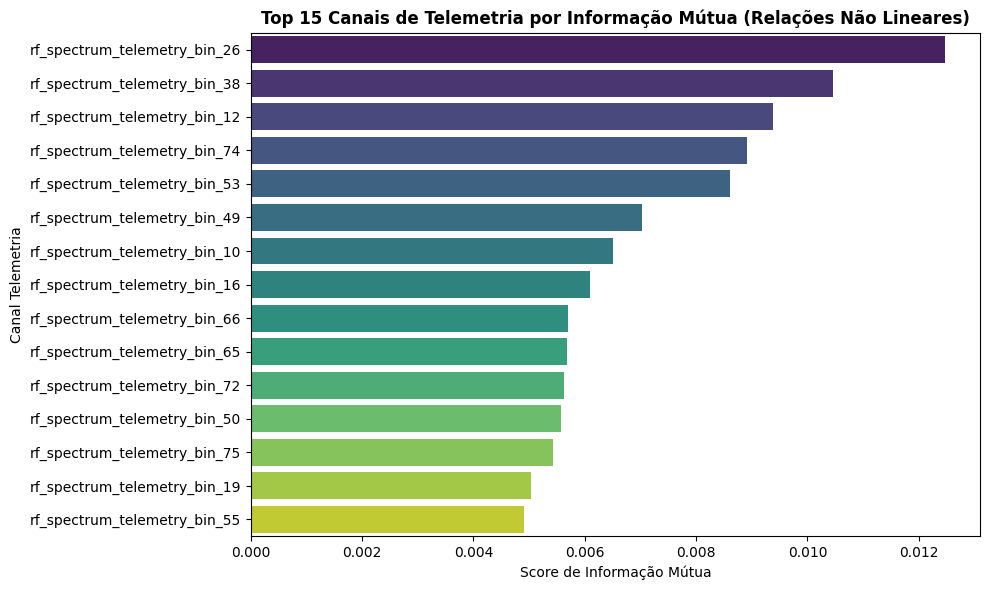

In [19]:
from sklearn.feature_selection import mutual_info_classif
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Isolar as colunas de telemetria e o alvo
cols_rf = [col for col in df_train.columns if 'rf_spectrum_telemetry' in col]
X = df_train[cols_rf]
y = df_train['unplanned_outage_next_30d']

# 2. Calcular a Informação Mútua
print("A calcular a Informação Mútua para as 75 colunas de telemetria (isso pode levar alguns segundos)... ")
mi_scores = mutual_info_classif(X, y, random_state=42)

# 3. Criar DataFrame com os resultados
df_mi = pd.DataFrame({
    'Canal Telemetria': cols_rf,
    'Mutual Information': mi_scores
}).sort_values(by='Mutual Information', ascending=False)

# 4. Mostrar o Top 15 canais com maior poder preditivo não linear
print("\n=== TOP 15 CANAIS DE TELEMETRIA COM MAIOR INFORMAÇÃO MÚTUA COM O ALVO ===")
display(df_mi.head(15))

# 5. Plotar os melhores resultados
plt.figure(figsize=(10, 6))
sns.barplot(data=df_mi.head(15), x='Mutual Information', y='Canal Telemetria', palette='viridis')
plt.title('Top 15 Canais de Telemetria por Informação Mútua (Relações Não Lineares)', fontsize=12, fontweight='bold')
plt.xlabel('Score de Informação Mútua')
plt.tight_layout()
plt.show()

## Outliers

In [21]:
#Variáveis operacionais selecionadas para a análise
selected_vars = ['rpm',
    'lubricant_dielectric_constant',
    'bearing_clearance_efficiency',
    'vibration_radial_rms_mm_s',
    'vibration_axial_rms_mm_s',
    'exhaust_temp_deviation_c',
    'temperature_sensor_2_c',
    'oil_particle_count_log']

# Verificar quais as variáveis existentes no conjunto de treino
variaveis_existentes = [col for col in selected_vars
    if col in df_train.columns]

# Identificar variáveis que não foram encontradas
variaveis_em_falta = [col for col in selected_vars
    if col not in df_train.columns]

# Confirmar que todas as variáveis selecionadas são numéricas
variaveis_numericas = [col for col in variaveis_existentes
    if pd.api.types.is_numeric_dtype(df_train[col])]

# Identificar eventuais variáveis não numéricas
variaveis_nao_numericas = [col for col in variaveis_existentes
    if col not in variaveis_numericas]

print("SELEÇÃO DE VARIÁVEIS PARA ANÁLISE DE OUTLIERS")
print(f"\nVariáveis inicialmente selecionadas: {len(selected_vars)}")
print(f"Variáveis existentes no treino: {len(variaveis_existentes)}")
print(f"Variáveis numéricas válidas: {len(variaveis_numericas)}")

print("\nVariáveis selecionadas:")
for col in variaveis_numericas:
    print(f"{col}")

if variaveis_em_falta:
    print("\nVariáveis não encontradas:")
    for col in variaveis_em_falta:
        print(f"{col}")

if variaveis_nao_numericas:
    print("\nVariáveis não numéricas:")
    for col in variaveis_nao_numericas:
        print(f"{col}")

# Criar tabela de caracterização inicial
resumo_selected_vars = pd.DataFrame({"variavel": variaveis_numericas,
    "valores_validos": [df_train[col].notna().sum()
        for col in variaveis_numericas],
    "valores_em_falta": [df_train[col].isna().sum()
        for col in variaveis_numericas],
    "valores_distintos": [df_train[col].nunique()
        for col in variaveis_numericas]})

display(resumo_selected_vars)

SELEÇÃO DE VARIÁVEIS PARA ANÁLISE DE OUTLIERS

Variáveis inicialmente selecionadas: 8
Variáveis existentes no treino: 8
Variáveis numéricas válidas: 8

Variáveis selecionadas:
rpm
lubricant_dielectric_constant
bearing_clearance_efficiency
vibration_radial_rms_mm_s
vibration_axial_rms_mm_s
exhaust_temp_deviation_c
temperature_sensor_2_c
oil_particle_count_log


,variavel,valores_validos,valores_em_falta,valores_distintos
0,rpm,8000,0,8000
1,lubricant_dielectric_constant,7754,246,7754
2,bearing_clearance_efficiency,8000,0,7995
3,vibration_radial_rms_mm_s,8000,0,8000
4,vibration_axial_rms_mm_s,7607,393,6880
5,exhaust_temp_deviation_c,8000,0,7987
6,temperature_sensor_2_c,8000,0,8000
7,oil_particle_count_log,8000,0,8000


**Df com e sem outliers**

In [22]:
import pandas as pd
import numpy as np

# Variáveis numéricas operacionais selecionadas
variaveis_analise = [
    'rpm',
    'lubricant_dielectric_constant',
    'bearing_clearance_efficiency',
    'vibration_radial_rms_mm_s',
    'vibration_axial_rms_mm_s',
    'exhaust_temp_deviation_c',
    'temperature_sensor_2_c',
    'oil_particle_count_log'
]

# Inicializar uma máscara booleana de linhas sem outliers (tudo True inicialmente)
mascara_sem_outliers = pd.Series(True, index=df_train.index)

# Aplicar o critério IQR para cada variável selecionada
for col in variaveis_analise:
    if col in df_train.columns:
        Q1 = df_train[col].quantile(0.25)
        Q3 = df_train[col].quantile(0.75)
        IQR = Q3 - Q1
        limite_inferior = Q1 - 1.5 * IQR
        limite_superior = Q3 + 1.5 * IQR

        # Atualizar a máscara identificando quem está dentro dos limites (ou é nulo, mantendo para não perder dados por nulos aqui)
        dentro_limites = (df_train[col] >= limite_inferior) & (df_train[col] <= limite_superior) | df_train[col].isna()
        mascara_sem_outliers = mascara_sem_outliers & dentro_limites

# Criar os DataFrames com e sem outliers
df_sem_outliers = df_train[mascara_sem_outliers].copy()
df_com_outliers = df_train[~mascara_sem_outliers].copy()

print(f"Dataset Original: {df_train.shape[0]} linhas")
print(f"Dataset Sem Outliers: {df_sem_outliers.shape[0]} linhas")
print(f"Dataset Apenas com Outliers: {df_com_outliers.shape[0]} linhas")

Dataset Original: 8000 linhas
Dataset Sem Outliers: 7723 linhas
Dataset Apenas com Outliers: 277 linhas


### Pré-processamento

In [ ]:
target = df_train['unplanned_outage_next_30d']
features = df_train.drop(columns=['unplanned_outage_next_30d'])

features_importantes = ["oil_particle_count_iso",
                        "post_shutdown_log_delta",
                        "recent_alarm_event_codes", "lubricant_dielectric_constant",
                        "bearing_clearance_efficiency", "vibration_radial_rms_mm_s",
                        "vibration_axial_rms_mm_s",
                        "exhaust_temp_deviation_c", "temperature_sensor_2_c",
                        "rf_spectrum_telemetry_bin_12",
                        "rf_spectrum_telemetry_bin_26", "rf_spectrum_telemetry_bin_38",
                        ]


df_treino = features[features_importantes]

#### Criar Features


In [24]:
import numpy as np

def add_vibration_features(df):

    df = df.copy()

    axial = df["vibration_axial_rms_mm_s"]
    radial = df["vibration_radial_rms_mm_s"]

    df["vibration_magnitude"] = np.sqrt(
        axial**2 + radial**2
    )

    df["vibration_imbalance"] = (
        np.abs(axial - radial) /
        (axial + radial).replace(0, np.nan)
    )

    return df

df = add_vibration_features(df_train)
print(df.columns)

Index(['rf_spectrum_telemetry_bin_43', 'oil_particle_count_log',
       'rf_spectrum_telemetry_bin_27', 'cycle_index',
       'rf_spectrum_telemetry_bin_58', 'rf_spectrum_telemetry_bin_51',
       'post_shutdown_log_delta', 'rf_spectrum_telemetry_bin_11',
       'rf_spectrum_telemetry_bin_25', 'rf_spectrum_telemetry_bin_17',
       'rf_spectrum_telemetry_bin_30', 'rf_spectrum_telemetry_bin_32',
       'rf_spectrum_telemetry_bin_52', 'rf_spectrum_telemetry_bin_04',
       'rf_spectrum_telemetry_bin_44', 'rf_spectrum_telemetry_bin_40',
       'rf_spectrum_telemetry_bin_47', 'rf_spectrum_telemetry_bin_55',
       'rf_spectrum_telemetry_bin_36', 'rf_spectrum_telemetry_bin_41',
       'rf_spectrum_telemetry_bin_34', 'rf_spectrum_telemetry_bin_71',
       'rf_spectrum_telemetry_bin_61', 'rf_spectrum_telemetry_bin_48',
       'rf_spectrum_telemetry_bin_18', 'recent_alarm_event_codes',
       'rf_spectrum_telemetry_bin_22', 'rf_spectrum_telemetry_bin_57',
       'rf_spectrum_telemetry_bin_15',

In [25]:
# Variáveis identificadas como data leakage
leakage_cols = [
    "post_shutdown_log_delta",
    "recent_alarm_event_codes",
    "post_incident_triage_metric"
]

# Features selecionadas inicialmente
features_importantes = [
    "oil_particle_count_iso",
    "post_shutdown_log_delta",
    "lubricant_dielectric_constant",
    "bearing_clearance_efficiency",
    "vibration_radial_rms_mm_s",
    "vibration_axial_rms_mm_s",
    "exhaust_temp_deviation_c",
    "temperature_sensor_2_c",
    "rf_spectrum_telemetry_bin_12",
    "rf_spectrum_telemetry_bin_26",
    "rf_spectrum_telemetry_bin_38"
]

# Remover automaticamente as features com leakage
features_modelo = [
    col for col in features_importantes
    if col not in leakage_cols
]

print("Features excluídas:", leakage_cols)
print("Features originais utilizadas:", features_modelo)

Features excluídas: ['post_shutdown_log_delta', 'recent_alarm_event_codes', 'post_incident_triage_metric']
Features originais utilizadas: ['oil_particle_count_iso', 'lubricant_dielectric_constant', 'bearing_clearance_efficiency', 'vibration_radial_rms_mm_s', 'vibration_axial_rms_mm_s', 'exhaust_temp_deviation_c', 'temperature_sensor_2_c', 'rf_spectrum_telemetry_bin_12', 'rf_spectrum_telemetry_bin_26', 'rf_spectrum_telemetry_bin_38']


In [26]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

X_train = df_train[features_modelo]
y_train = df_train["unplanned_outage_next_30d"]

numeric_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    exclude=["number"]
).columns.tolist()

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(
        strategy="median",
        add_indicator=True
    )),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(
        strategy="most_frequent"
    )),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

In [27]:
import numpy as np

from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedGroupKFold, cross_val_predict
from sklearn.metrics import f1_score

# Rede neuronal
mlp = MLPClassifier(
    hidden_layer_sizes=(64, 32),
    activation="relu",
    solver="adam",
    alpha=0.001,
    learning_rate_init=0.001,
    max_iter=500,
    early_stopping=False,
    random_state=42
)

# Pipeline: pré-processamento + rede neuronal
modelo_mlp = Pipeline([
    ("preprocessor", preprocessor),
    ("model", mlp)
])

In [28]:
cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

groups = df_train["machine_serial_id"]

# Previsões out-of-fold
y_pred_oof = cross_val_predict(
    modelo_mlp,
    X_train,
    y_train,
    cv=cv,
    groups=groups,
    method="predict",
    n_jobs=-1
)

# F1-score
f1 = f1_score(y_train, y_pred_oof)

print(f"F1-score da rede neuronal: {f1:.4f}")

F1-score da rede neuronal: 0.6275


Testar vários tamanhos da rede

In [ ]:
import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import StratifiedGroupKFold, cross_val_predict
from sklearn.metrics import f1_score

# Validação cruzada agrupada por máquina
cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Identificador das máquinas
groups = df_train["machine_serial_id"]

# Arquiteturas a testar
architectures = [
    (64, 32),
    (128, 64),
    (128, 64, 32),
    (256, 128, 64),
    (128, 128)
]

results = []
predictions = {}

for architecture in architectures:

    mlp = MLPClassifier(
        hidden_layer_sizes=architecture,
        activation="relu",
        solver="adam",
        alpha=0.001,
        learning_rate_init=0.0005,
        batch_size=64,
        max_iter=700,
        early_stopping=False,
        random_state=42
    )

    pipeline = Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("model", mlp)
    ])

    # Probabilidades out-of-fold
    probs = cross_val_predict(
        pipeline,
        X_train,
        y_train,
        groups=groups,
        cv=cv,
        method="predict_proba",
        n_jobs=-1
    )[:, 1]

    # Previsões com threshold 0.5
    preds = (probs >= 0.5).astype(int)

    score = f1_score(
        y_train,
        preds,
        zero_division=0
    )

    results.append({
        "Arquitetura": str(architecture),
        "F1": score
    })

    predictions[architecture] = probs

# Ordenar resultados pelo F1
results_df = pd.DataFrame(results).sort_values(
    "F1",
    ascending=False
)

print(results_df.round(4))